<a href="https://colab.research.google.com/github/Shihabalfaj6062/aiml-lab-problem-1-/blob/main/stroke_ml_comparative_study_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparative Study of Machine Learning Models for Stroke Prediction

This notebook evaluates Logistic Regression, Decision Tree, Random Forest, SVM, and an Artificial Neural Network (MLP) on the supplied processed stroke dataset. It reports Accuracy, Precision, Recall, F1-score, ROC-AUC, confusion matrices, ROC curves, and a top-three comparison.

**Before running:** place `stroke_processed.csv` in the same folder as this notebook and install dependencies with `pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn`.

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

In [2]:
from google.colab import files
import pandas as pd
import io

print("Upload your processed stroke dataset (CSV file)")

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("\nDataset uploaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Upload your processed stroke dataset (CSV file)


Saving stroke_processed.csv to stroke_processed.csv

Dataset uploaded successfully!
Dataset shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1



Column names:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Missing values:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


Features: 10
Records: 5110

Target distribution:
stroke
0    4861
1     249
Name: count, dtype: int64

Training records: 4088
Testing records: 1022

Training: Logistic Regression
Accuracy: 0.7515
Precision: 0.1408
Recall: 0.8
F1-Score: 0.2395
ROC-AUC: 0.8387

Training: Decision Tree
Accuracy: 0.7407
Precision: 0.1228
Recall: 0.7
F1-Score: 0.209
ROC-AUC: 0.7735

Training: Random Forest
Accuracy: 0.9432
Precision: 0.3
Recall: 0.12
F1-Score: 0.1714
ROC-AUC: 0.8187

Training: SVM
Accuracy: 0.7358
Precision: 0.1181
Recall: 0.68
F1-Score: 0.2012
ROC-AUC: 0.7856

Training: ANN
Accuracy: 0.8317
Precision: 0.128
Recall: 0.42
F1-Score: 0.1963
ROC-AUC: 0.7665

========== MODEL COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7515,0.1408,0.8000,0.2395,0.8387
1,Decision Tree,0.7407,0.1228,0.7000,0.2090,0.7735
2,SVM,0.7358,0.1181,0.6800,0.2012,0.7856
3,ANN,0.8317,0.1280,0.4200,0.1963,0.7665
4,Random Forest,0.9432,0.3000,0.1200,0.1714,0.8187


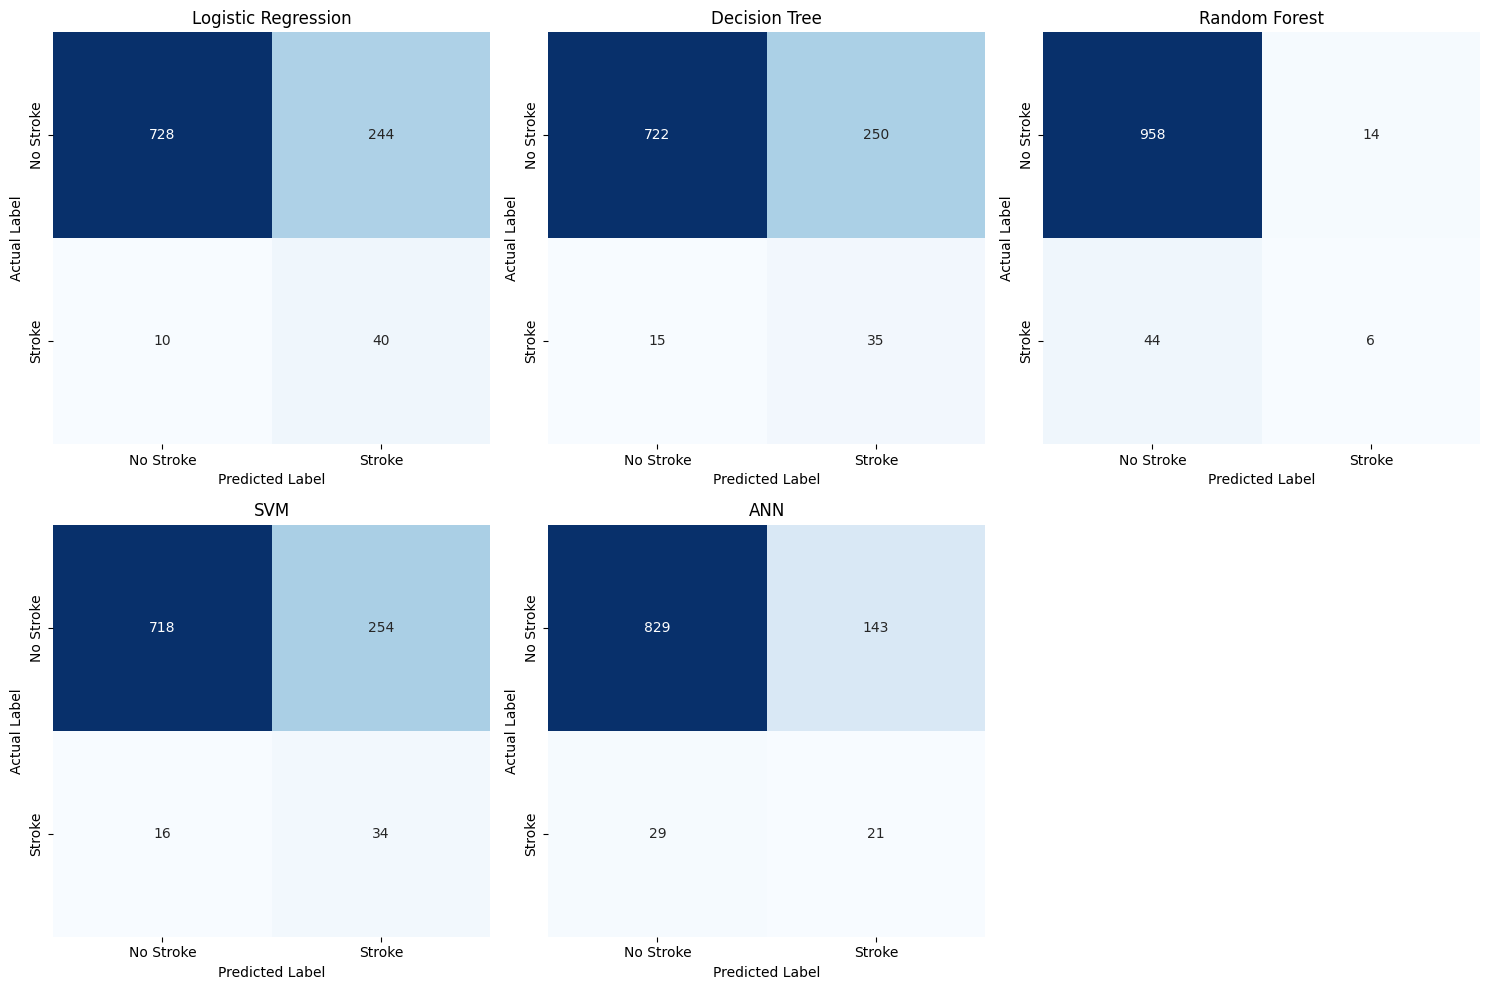

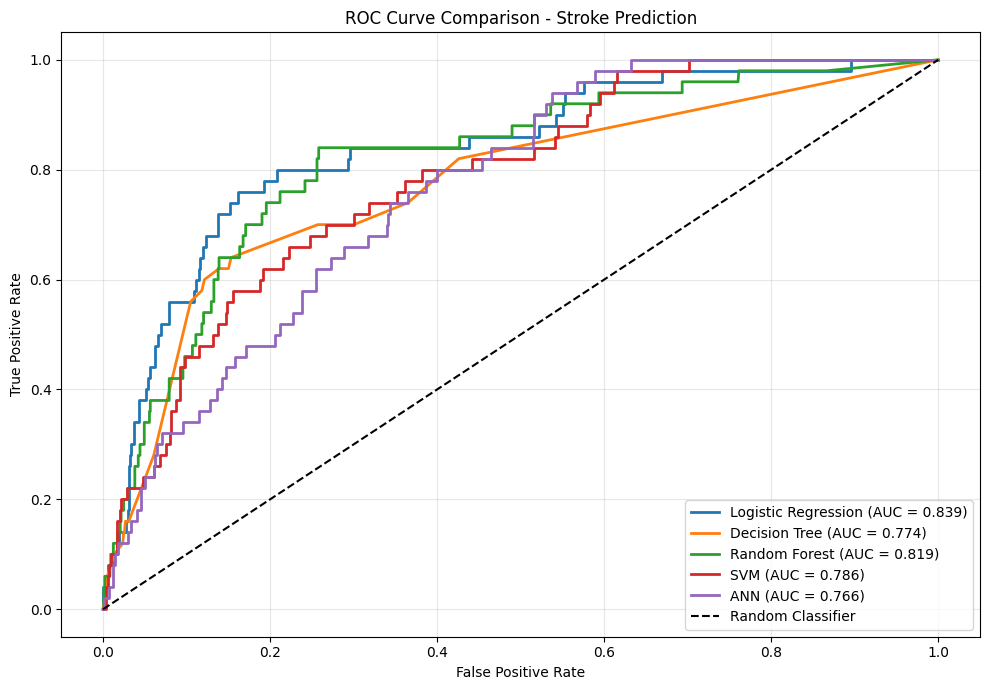


========== TOP 3 MODELS ==========


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.751468,0.140845,0.80,0.239521,0.838704
1,Decision Tree,0.740705,0.122807,0.70,0.208955,0.773519
2,SVM,0.735812,0.118056,0.68,0.201183,0.785617



========== TOP 3 STROKE RISK ANALYSIS ==========


,Model,True Positives,False Positives,True Negatives,False Negatives,Stroke Cases Detected,Stroke Cases Missed,Recall
0,Logistic Regression,40,244,728,10,40,10,0.80
1,Decision Tree,35,250,722,15,35,15,0.70
2,SVM,34,254,718,16,34,16,0.68


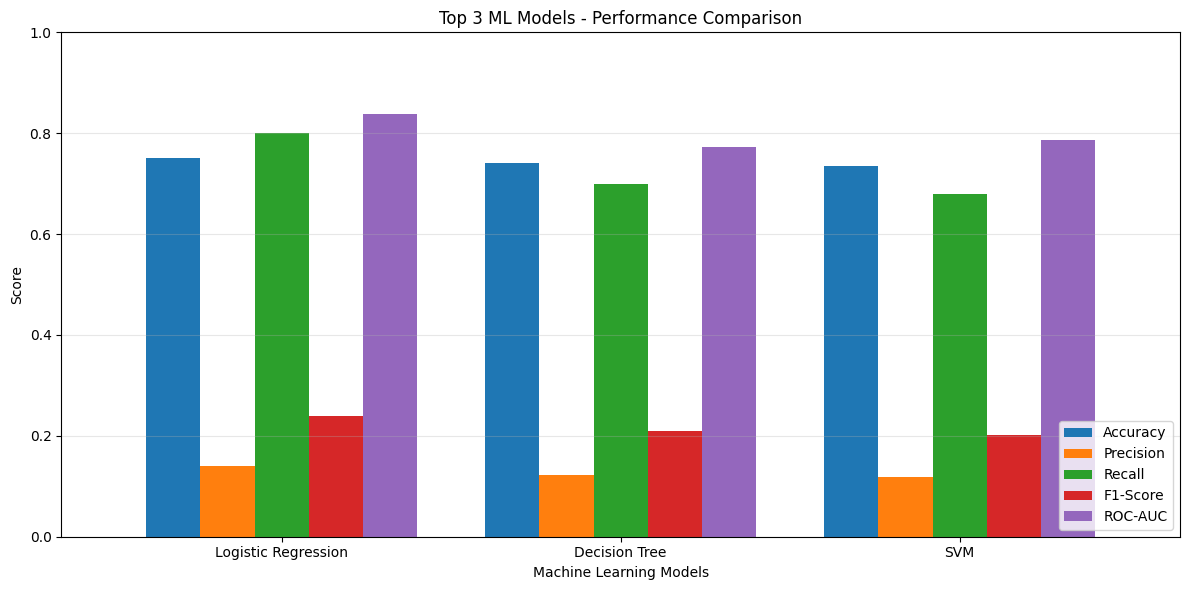


Results exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


========== EXPERIMENT COMPLETED ==========


In [3]:
# ==========================================
# STROKE PREDICTION - FIVE ML MODELS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    classification_report
)

warnings.filterwarnings("ignore")

# ==========================================
# 1. DATA PREPROCESSING
# ==========================================

# Identify target column
target = next(
    (col for col in df.columns if col.lower() == "stroke"),
    None
)

if target is None:
    raise ValueError("Target column 'stroke' not found!")

# Remove rows with missing target
df = df.dropna(subset=[target]).copy()

# Convert target into binary format
if not set(df[target].unique()).issubset({0, 1}):
    le = LabelEncoder()
    df[target] = le.fit_transform(df[target].astype(str))

# Separate features and target
X = df.drop(columns=[target])
y = df[target].astype(int)

# Remove identifier column if present
id_columns = [
    col for col in X.columns
    if col.lower() in ["id", "patient_id", "patientid"]
]

X = X.drop(columns=id_columns)

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

print("Features:", X.shape[1])
print("Records:", X.shape[0])

print("\nTarget distribution:")
print(y.value_counts())

# ==========================================
# 2. TRAIN TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# ==========================================
# 3. FEATURE SCALING AND ENCODING
# ==========================================

numeric_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["int64", "float64", "int32", "float32"]
).columns.tolist()

# Support both newer and older sklearn versions
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

numeric_transformer = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# ==========================================
# 4. DEFINE FIVE ML MODELS
# ==========================================

models = {

    "Logistic Regression": SklearnPipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ]),

    "Decision Tree": SklearnPipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced",
            max_depth=6,
            min_samples_leaf=10,
            random_state=42
        ))
    ]),

    "Random Forest": SklearnPipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=400,
            class_weight="balanced_subsample",
            min_samples_leaf=3,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        ))
    ]),

    "SVM": SklearnPipeline([
        ("preprocessor", preprocessor),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "ANN": Pipeline([
        ("preprocessor", preprocessor),
        ("oversampler", RandomOverSampler(
            random_state=42
        )),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=True,
            random_state=42
        ))
    ])
}

# ==========================================
# 5. TRAIN AND EVALUATE ALL MODELS
# ==========================================

results = []
confusion_matrices = {}
roc_probabilities = {}
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Probability of stroke (class 1)
    class_index = list(model.classes_).index(1)
    y_prob = model.predict_proba(X_test)[:, class_index]

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    auc = roc_auc_score(y_test, y_prob)

    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    # Store results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    confusion_matrices[name] = cm
    roc_probabilities[name] = y_prob
    trained_models[name] = model

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))
    print("ROC-AUC:", round(auc, 4))

# ==========================================
# 6. COMPARATIVE PERFORMANCE TABLE
# ==========================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("\n========== MODEL COMPARISON ==========")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

# ==========================================
# 7. CONFUSION MATRIX OF EACH MODEL
# ==========================================

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes = axes.flatten()

for i, (name, cm) in enumerate(
    confusion_matrices.items()
):

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No Stroke", "Stroke"],
        yticklabels=["No Stroke", "Stroke"],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

# ==========================================
# 8. ROC-AUC CURVES
# ==========================================

plt.figure(figsize=(10, 7))

for name, y_prob in roc_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test, y_prob
    )

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison - Stroke Prediction")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 9. TOP THREE MODELS
# ==========================================

top3 = results_df.head(3)

print("\n========== TOP 3 MODELS ==========")

display(top3)

# ==========================================
# 10. STROKE RISK PREDICTION ANALYSIS
# ==========================================

risk_results = []

for name in top3["Model"]:

    cm = confusion_matrices[name]

    tn, fp, fn, tp = cm.ravel()

    risk_results.append({
        "Model": name,
        "True Positives": tp,
        "False Positives": fp,
        "True Negatives": tn,
        "False Negatives": fn,
        "Stroke Cases Detected": tp,
        "Stroke Cases Missed": fn,
        "Recall": tp / (tp + fn) if (tp + fn) else 0
    })

risk_df = pd.DataFrame(risk_results)

print("\n========== TOP 3 STROKE RISK ANALYSIS ==========")

display(risk_df)

# ==========================================
# 11. TOP THREE MODEL COMPARISON GRAPH
# ==========================================

top3_plot = top3.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
]

top3_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Top 3 ML Models - Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 12. EXPORT RESULTS
# ==========================================

results_df.to_csv(
    "stroke_model_comparison.csv",
    index=False
)

risk_df.to_csv(
    "stroke_top3_risk_analysis.csv",
    index=False
)

print("\nResults exported successfully!")

from google.colab import files

files.download("stroke_model_comparison.csv")
files.download("stroke_top3_risk_analysis.csv")

print("\n========== EXPERIMENT COMPLETED ==========")